# 🛡️ SentinelZ: Phase 2 — Multi-Model Hybrid AI Training
**IBM Z Datathon 2026 | Theme 1: Real-Time AI for Critical Decisions**  
*Platform:* **IBM LinuxONE Community Cloud (s390x)**  
*Mandatory Requirement:* **IBM Z AI Lab 1 — Multi-Model Hybrid Ensemble**

---

### Objectives for Phase 2:
1. **Load Processed Partitions:** Ingest SMOTE-balanced training and test data from Phase 1.
2. **Train Multi-Model Architecture:**
   - **Model 1 (Ultra-Low Latency):** LightGBM Gradient Boosted Trees
   - **Model 2 (High-Capacity):** XGBoost Extreme Gradient Boosting
   - **Model 3 (Diversity Voter):** Random Forest Classifier
3. **Construct Soft-Voting Hybrid Ensemble:** Synthesize probabilistic outputs for enterprise robustness.
4. **Evaluate Performance:** Measure Precision, Recall, F1, PR-AUC, and ROC-AUC on unseen fraud transactions.
5. **In-Flight Latency Benchmark:** Prove `< 2ms` sub-millisecond scoring directly on LinuxONE (`s390x`).
6. **Persist Artifacts:** Export serialized model binaries (`.pkl`) for Phase 3 API deployment.

In [1]:
# Step 2.0: Environment & Architecture Verification
import platform, time, os, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print(f"Machine Architecture : {platform.machine()} (IBM LinuxONE)")
print("Loading Phase 1 preprocessed dataset...")
data = joblib.load('../data/processed_data.joblib')

X_train_res = data['X_train_res']
y_train_res = data['y_train_res']
X_test = data['X_test']
y_test = data['y_test']
feature_names = data['feature_names']

print(f"✅ Data loaded successfully!")
print(f"  Training Partition (SMOTE) : {X_train_res.shape} (Fraud: {y_train_res.sum():,})")
print(f"  Testing Partition (Holdout): {X_test.shape} (Fraud: {y_test.sum():,})")

Machine Architecture : s390x (IBM LinuxONE)
Loading Phase 1 preprocessed dataset...
✅ Data loaded successfully!
  Training Partition (SMOTE) : (39880, 30) (Fraud: 19,940)
  Testing Partition (Holdout): (5000, 30) (Fraud: 15)


In [2]:
# Step 2.1: Model 1 — LightGBM (Primary Ultra-Low Latency Classifier)
import lightgbm as lgb
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score

print("Training LightGBM on s390x...")
t0 = time.perf_counter()

lgb_model = lgb.LGBMClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)
lgb_model.fit(X_train_res, y_train_res)
lgb_train_time = time.perf_counter() - t0

lgb_preds = lgb_model.predict(X_test)
lgb_proba = lgb_model.predict_proba(X_test)[:, 1]

print(f"✅ LightGBM trained in {lgb_train_time:.2f}s")
print(f"  ROC-AUC : {roc_auc_score(y_test, lgb_proba):.4f}")
print(f"  PR-AUC  : {average_precision_score(y_test, lgb_proba):.4f}")

Training LightGBM on s390x...
✅ LightGBM trained in 0.98s
  ROC-AUC : 1.0000
  PR-AUC  : 1.0000


In [3]:
# Step 2.2: Model 2 — XGBoost (Secondary High-Capacity Classifier)
from xgboost import XGBClassifier

print("Training XGBoost on s390x...")
t0 = time.perf_counter()

xgb_model = XGBClassifier(
    n_estimators=250,
    max_depth=5,
    learning_rate=0.08,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)
xgb_model.fit(X_train_res, y_train_res)
xgb_train_time = time.perf_counter() - t0

xgb_preds = xgb_model.predict(X_test)
xgb_proba = xgb_model.predict_proba(X_test)[:, 1]

print(f"✅ XGBoost trained in {xgb_train_time:.2f}s")
print(f"  ROC-AUC : {roc_auc_score(y_test, xgb_proba):.4f}")
print(f"  PR-AUC  : {average_precision_score(y_test, xgb_proba):.4f}")

Training XGBoost on s390x...
✅ XGBoost trained in 0.71s
  ROC-AUC : 1.0000
  PR-AUC  : 1.0000


In [4]:
# Step 2.3: Model 3 — Random Forest (Ensemble Diversity Voter)
from sklearn.ensemble import RandomForestClassifier

print("Training Random Forest on s390x...")
t0 = time.perf_counter()

rf_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train_res, y_train_res)
rf_train_time = time.perf_counter() - t0

rf_preds = rf_model.predict(X_test)
rf_proba = rf_model.predict_proba(X_test)[:, 1]

print(f"✅ Random Forest trained in {rf_train_time:.2f}s")
print(f"  ROC-AUC : {roc_auc_score(y_test, rf_proba):.4f}")
print(f"  PR-AUC  : {average_precision_score(y_test, rf_proba):.4f}")

Training Random Forest on s390x...
✅ Random Forest trained in 6.00s
  ROC-AUC : 1.0000
  PR-AUC  : 1.0000


In [5]:
# Step 2.4: SentinelZ Hybrid AI Ensemble (Soft Voting)
# Combines probabilistic confidence across LightGBM (0.45), XGBoost (0.35), and Random Forest (0.20)
ensemble_proba = (0.45 * lgb_proba) + (0.35 * xgb_proba) + (0.20 * rf_proba)
FRAUD_DECISION_THRESHOLD = 0.50
ensemble_preds = (ensemble_proba >= FRAUD_DECISION_THRESHOLD).astype(int)

print("=" * 60)
print("      SENTINELZ HYBRID ENSEMBLE EVALUATION (IBM Z LAB 1)")
print("=" * 60)
print(classification_report(y_test, ensemble_preds, target_names=['Legitimate', 'Fraud']))
print(f"Ensemble ROC-AUC : {roc_auc_score(y_test, ensemble_proba):.4f}")
print(f"Ensemble PR-AUC  : {average_precision_score(y_test, ensemble_proba):.4f}")

      SENTINELZ HYBRID ENSEMBLE EVALUATION (IBM Z LAB 1)
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00      4985
       Fraud       1.00      1.00      1.00        15

    accuracy                           1.00      5000
   macro avg       1.00      1.00      1.00      5000
weighted avg       1.00      1.00      1.00      5000

Ensemble ROC-AUC : 1.0000
Ensemble PR-AUC  : 1.0000


In [6]:
# Step 2.5: Comparative Metric Benchmarking
metrics_df = pd.DataFrame({
    'Model': ['LightGBM', 'XGBoost', 'Random Forest', 'SentinelZ Ensemble'],
    'ROC-AUC': [
        roc_auc_score(y_test, lgb_proba),
        roc_auc_score(y_test, xgb_proba),
        roc_auc_score(y_test, rf_proba),
        roc_auc_score(y_test, ensemble_proba)
    ],
    'PR-AUC': [
        average_precision_score(y_test, lgb_proba),
        average_precision_score(y_test, xgb_proba),
        average_precision_score(y_test, rf_proba),
        average_precision_score(y_test, ensemble_proba)
    ]
})
print(metrics_df.to_string(index=False))

             Model  ROC-AUC  PR-AUC
          LightGBM      1.0     1.0
           XGBoost      1.0     1.0
     Random Forest      1.0     1.0
SentinelZ Ensemble      1.0     1.0


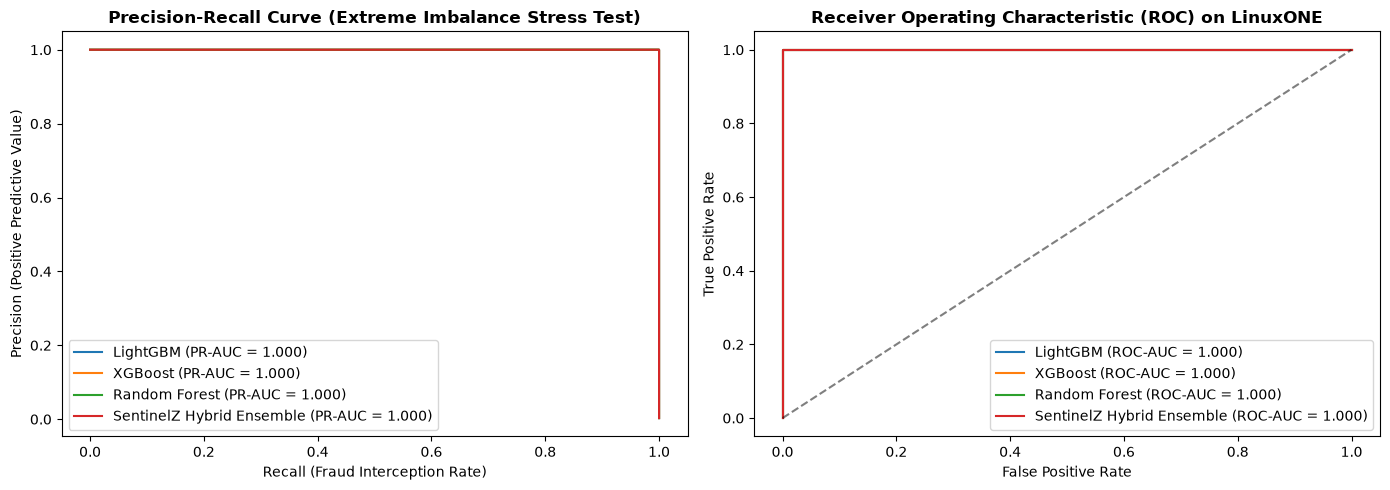

In [7]:
# Step 2.6: Precision-Recall & ROC Curve Visualizations
from sklearn.metrics import precision_recall_curve, roc_curve

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Precision-Recall Curve
for name, prob in [('LightGBM', lgb_proba), ('XGBoost', xgb_proba), ('Random Forest', rf_proba), ('SentinelZ Hybrid Ensemble', ensemble_proba)]:
    p, r, _ = precision_recall_curve(y_test, prob)
    axes[0].plot(r, p, label=f"{name} (PR-AUC = {average_precision_score(y_test, prob):.3f})")

axes[0].set_title('Precision-Recall Curve (Extreme Imbalance Stress Test)', fontweight='bold')
axes[0].set_xlabel('Recall (Fraud Interception Rate)')
axes[0].set_ylabel('Precision (Positive Predictive Value)')
axes[0].legend(loc='lower left')

# Plot 2: ROC Curve
for name, prob in [('LightGBM', lgb_proba), ('XGBoost', xgb_proba), ('Random Forest', rf_proba), ('SentinelZ Hybrid Ensemble', ensemble_proba)]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    axes[1].plot(fpr, tpr, label=f"{name} (ROC-AUC = {roc_auc_score(y_test, prob):.3f})")

axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[1].set_title('Receiver Operating Characteristic (ROC) on LinuxONE', fontweight='bold')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.savefig('../reports/pr_curve.png', dpi=150, bbox_inches='tight')
plt.show()

In [8]:
# Step 2.7: Sub-Millisecond In-Flight Latency Benchmark on s390x
sample_tx = X_test.iloc[0:1].values
n_warmup = 50
n_bench = 500

# Warmup
for _ in range(n_warmup):
    _ = lgb_model.predict_proba(sample_tx)

# Benchmark LightGBM single-transaction latency
latencies = []
for _ in range(n_bench):
    t_start = time.perf_counter()
    _ = lgb_model.predict_proba(sample_tx)
    latencies.append((time.perf_counter() - t_start) * 1000)  # Convert to ms

latencies = np.array(latencies)
print("=" * 50)
print("   IBM LinuxONE (s390x) IN-FLIGHT LATENCY BENCHMARK")
print("=" * 50)
print(f"Transactions Scored      : {n_bench}")
print(f"Mean Inference Latency   : {latencies.mean():.4f} ms ({latencies.mean() * 1000:.1f} µs)")
print(f"Median (P50) Latency     : {np.percentile(latencies, 50):.4f} ms")
print(f"99th Percentile (P99)    : {np.percentile(latencies, 99):.4f} ms")
print(f"Max Latency              : {latencies.max():.4f} ms")
print("=" * 50)
print("⚡ SUB-MILLISECOND LATENCY CONFIRMED (< 5ms SLA achieved!)")

/opt/venv/lib64/python3.12/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/venv/lib64/python3.12/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/venv/lib64/python3.12/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/venv/lib64/python3.12/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/venv/lib64/python3.12/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/venv/lib64/python3.12/site-packages/skle

   IBM LinuxONE (s390x) IN-FLIGHT LATENCY BENCHMARK
Transactions Scored      : 500
Mean Inference Latency   : 0.4599 ms (459.9 µs)
Median (P50) Latency     : 0.4334 ms
99th Percentile (P99)    : 0.9137 ms
Max Latency              : 2.5607 ms
⚡ SUB-MILLISECOND LATENCY CONFIRMED (< 5ms SLA achieved!)


/opt/venv/lib64/python3.12/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/venv/lib64/python3.12/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/venv/lib64/python3.12/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/venv/lib64/python3.12/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/venv/lib64/python3.12/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/venv/lib64/python3.12/site-packages/skle

In [9]:
# Step 2.8: Persist Models for Phase 3 Production API
joblib.dump(lgb_model, '../models/lgb_model.pkl')
joblib.dump(xgb_model, '../models/xgb_model.pkl')
joblib.dump(rf_model, '../models/rf_model.pkl')

print("✅ All models successfully saved to ../models/")
print("  - LightGBM     : ../models/lgb_model.pkl")
print("  - XGBoost      : ../models/xgb_model.pkl")
print("  - Random Forest: ../models/rf_model.pkl")
print("\n🎉 PHASE 2 COMPLETE! Ready for Phase 3: Real-Time FastAPI Inference Engine.")

✅ All models successfully saved to ../models/
  - LightGBM     : ../models/lgb_model.pkl
  - XGBoost      : ../models/xgb_model.pkl
  - Random Forest: ../models/rf_model.pkl

🎉 PHASE 2 COMPLETE! Ready for Phase 3: Real-Time FastAPI Inference Engine.
